# The lock-in amplifier for quantum sensing
### SymPy derivations, a digital lock-in that beats 1/f noise, and a field-tracking NV magnetometer

**In plain words.** Quantum sensors produce tiny signals on top of detector drift and flicker
(1/f) noise, which is worst at low frequencies. A **lock-in amplifier** solves this in two steps:
1. **wiggle** the thing you control (chop the light, or modulate the microwave frequency) at a
   known frequency $f_m$, where the noise is low;
2. **listen only at $f_m$**, by multiplying by a reference and averaging.

That turns a measurement that was hopeless at DC into a clean one. In an NV magnetometer, the
same trick also produces an error signal that lets the instrument **follow** a changing magnetic
field.

**Builds on:**
* `nv_magnetometer.ipynb` (ODMR line shape, sensitivity);
* `transimpedance_amplifier` (the photodiode front end before the lock-in);
* `pid_controller` (feedback).

Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as
well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import lockin_amplifier as L
from dgs import nv_magnetometer as nv
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. Mixing: multiplication shifts the signal to DC

Multiply the signal $A\cos(\omega t+\phi)$ by the reference $\cos\omega t$. A trig identity splits
the product into a DC term and a $2\omega$ term:

In [2]:
target, residual = L.mixer_products_symbolic()
display(sp.Eq(sp.Symbol("A cos(wt+phi) cos(wt)"), target)); print("identity residual:", residual)

identity residual: 0


Average over a period (an ideal low-pass filter) and only DC survives. With a second reference
in quadrature ($\sin\omega t$), you get both components. The usual factor 2 makes $X=A\cos\phi$:

In [3]:
X, Y, R, th = L.demod_symbolic()
display(sp.Eq(sp.Symbol("X"), X), sp.Eq(sp.Symbol("Y"), Y), sp.Eq(sp.Symbol("R"), R))

$R$ is the amplitude regardless of phase, and $\theta=\mathrm{atan2}(Y,X)$ is the phase. A
signal at the wrong frequency $\omega+\Delta\omega$ leaves a **beat** at $\Delta\omega$, which the
low-pass filter attenuates:

In [4]:
target, residual = L.off_frequency_rejection_symbolic()
display(sp.Eq(sp.Symbol("2A cos((w+dw)t) cos(wt)"), target)); print("residual:", residual)

residual: 0


Many lock-ins, and many simple circuits, use a **square-wave** reference. Its Fourier series
shows that it also listens at $3\omega$, $5\omega$, … with weights $1/3$, $1/5$, …:

In [5]:
for n, b in L.square_wave_reference_symbolic(4):
    print(f"harmonic {n}: coefficient {b}  (= {float(b):.4f})")

harmonic 1: coefficient 4/pi  (= 1.2732)
harmonic 3: coefficient 4/(3*pi)  (= 0.4244)
harmonic 5: coefficient 4/(5*pi)  (= 0.2546)
harmonic 7: coefficient 4/(7*pi)  (= 0.1819)


## 2. The low-pass filter sets the noise

An $n$-pole RC filter with time constant $\tau$ passes white noise as if it were a perfect
brick-wall filter of width ENBW (equivalent noise bandwidth). SymPy integrates $|H(f)|^2$:

In [6]:
tau = sp.symbols("tau", positive=True)
for n in (1, 2, 3, 4):
    print(f"{n}-pole: ENBW = {L.enbw_symbolic(n)}   99% settling = {L.settle_time(n, 1.0):.2f} tau")

1-pole: ENBW = 1/(4*tau)   99% settling = 4.61 tau
2-pole: ENBW = 1/(8*tau)   99% settling = 6.64 tau
3-pole: ENBW = 3/(32*tau)   99% settling = 8.41 tau
4-pole: ENBW = 5/(64*tau)   99% settling = 10.05 tau


Output noise is the noise density times $\sqrt{\text{ENBW}}$. More poles roll off
interference faster but settle more slowly. **Rule of thumb:** wait about 5–10 τ after any
change before reading the lock-in.

Check with a digital lock-in on a buried signal:

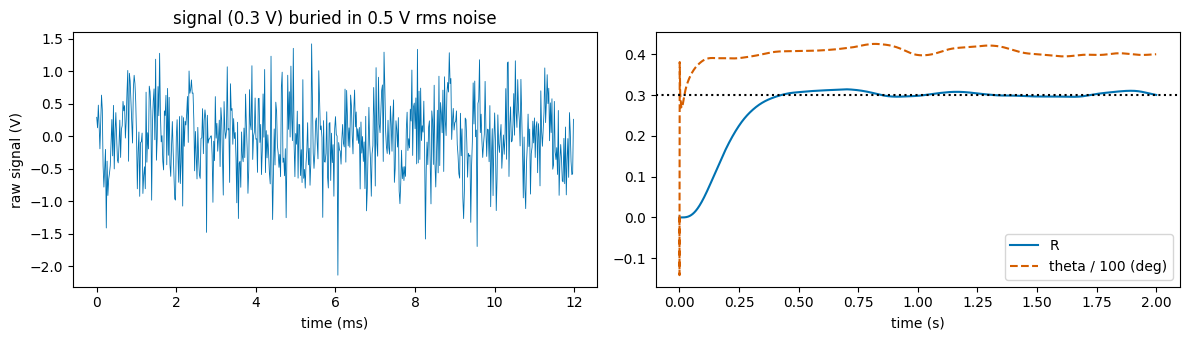

after settling: R = 0.3034 V (true 0.3),  theta = 40.8 deg (true 40)
Figure description: left, the raw trace looks like noise. Right, the lock-in output R (solid) settles onto the dotted 0.3 V line and the phase (dashed, scaled by 1/100) settles near 40 degrees.


In [7]:
fs, f0 = 50000.0, 1234.0
t = np.arange(int(2 * fs)) / fs
sig = 0.3 * np.cos(2*np.pi*f0*t + np.deg2rad(40)) + 0.5 * np.random.default_rng(0).normal(size=len(t))
X, Y, R, th = L.lockin(sig, t, f0, tau=0.05, order=4)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(t[:600]*1e3, sig[:600], lw=0.6); ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel("raw signal (V)"); ax[0].set_title("signal (0.3 V) buried in 0.5 V rms noise")
ax[1].plot(t, R, "-", label="R"); ax[1].plot(t, th/100, "--", label="theta / 100 (deg)")
ax[1].axhline(0.3, c="k", ls=":"); ax[1].set_xlabel("time (s)"); ax[1].legend(); plt.tight_layout(); plt.show()
k = int(0.5*fs); print(f"after settling: R = {R[k:].mean():.4f} V (true 0.3),  theta = {th[k:].mean():.1f} deg (true 40)")
print("Figure description: left, the raw trace looks like noise. Right, the lock-in output R (solid) settles onto the "
      "dotted 0.3 V line and the phase (dashed, scaled by 1/100) settles near 40 degrees.")

## 3. Why modulate: escaping 1/f noise

Real detectors have **flicker noise** with power spectral density $\propto1/f$, plus slow drift.
Two ways to measure a small signal $A$:
* **switched DC:** turn the source on and off every second and subtract;
* **lock-in:** chop the source at 1 kHz, where the noise floor is white, and demodulate.

Same signal, same noise, same total time:

switched DC        estimate   0.764 mV   scatter  3.916 mV   (true 1.0 mV)
lock-in at 1 kHz   estimate   0.992 mV   scatter  0.144 mV   (true 1.0 mV)


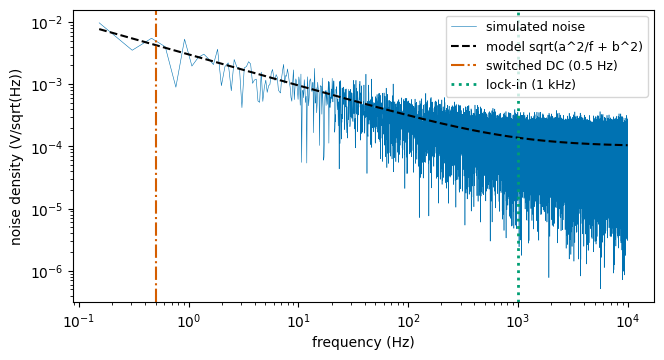

Figure description: noise spectral density falls as 1/sqrt(f) at low frequency and flattens to a white floor. The dash-dot line at 0.5 Hz (switched DC) sits high on the flicker slope; the dotted line at 1 kHz (lock-in) sits on the low white floor.


In [8]:
res = [L.dc_vs_lockin_demo(rng=s) for s in range(5)]
for name, key in (("switched DC", "dc"), ("lock-in at 1 kHz", "lockin")):
    m = np.mean([r[key + "_mean"] for r in res]); sd = np.mean([r[key + "_std"] for r in res])
    print(f"{name:18s} estimate {m*1e3:7.3f} mV   scatter {sd*1e3:6.3f} mV   (true {res[0]['true']*1e3:.1f} mV)")
n = 2**17; dt = 1/20000
f = np.fft.rfftfreq(n, dt)[1:]
x = L.pink_noise(n, dt, 3e-3, 1e-4, rng=0)
psd = (np.abs(np.fft.rfft(x))**2 * 2 * dt / n)[1:]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.loglog(f, np.sqrt(psd), lw=0.4, color=OI[0], label="simulated noise")
ax.loglog(f, np.sqrt(3e-3**2/f + 1e-4**2), "k--", label="model sqrt(a^2/f + b^2)")
ax.axvline(0.5, color=OI[1], ls="-.", label="switched DC (0.5 Hz)"); ax.axvline(1000, color=OI[2], ls=":", lw=2, label="lock-in (1 kHz)")
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("noise density (V/sqrt(Hz))"); ax.legend(fontsize=9); plt.show()
print("Figure description: noise spectral density falls as 1/sqrt(f) at low frequency and flattens to a white floor. "
      "The dash-dot line at 0.5 Hz (switched DC) sits high on the flicker slope; the dotted line at 1 kHz (lock-in) "
      "sits on the low white floor.")

The switched-DC method can't even see the 1 mV signal; its scatter is several times larger.
The lock-in measures it with roughly 20–30× smaller scatter. The noise density at 1 kHz is about
30× lower than at 0.5 Hz, and the lock-in collects essentially all of that advantage.

## 4. Quantum sensing: frequency modulation on the NV resonance

For the NV magnetometer, modulate the **microwave frequency**: $f(t)=f_c+\delta\sin\omega_mt$.
Expand the fluorescence $S(f)$ in a Taylor series and project onto $\sin\omega_mt$. SymPy finds the
first-harmonic lock-in output:

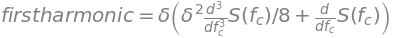

In [9]:
sp.Eq(sp.Symbol("first harmonic"), L.fm_first_harmonic_symbolic())

For small $\delta$, the lock-in reads $\delta\,S'(f_c)$: **the derivative of the resonance**. A
dip turns into a dispersive curve that crosses zero exactly on resonance, with a sign that says
which way to steer. That's an error signal.

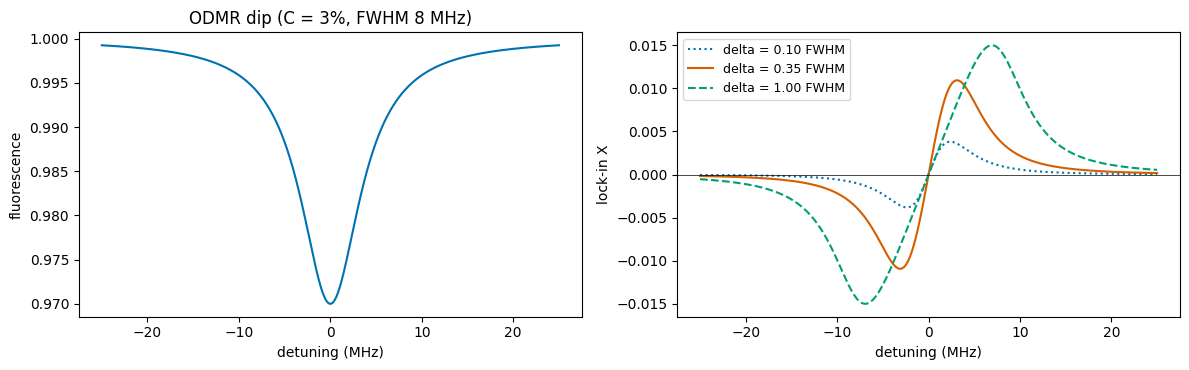

optimal depth = 0.3536 FWHM  (1/(2 sqrt 2) = 0.3536);  zero-crossing slope = 5.774e-09 /Hz (8C/(3 sqrt3 Gamma) = 5.774e-09)
Figure description: left, a Lorentzian fluorescence dip. Right, the lock-in error signal for three modulation depths: each is odd about zero detuning; the optimal depth (solid) has the steepest zero crossing, a small depth (dotted) is weak, and a large depth (dashed) is broadened.


In [10]:
C, G = 0.03, 8e6
det = np.linspace(-25e6, 25e6, 801)
dopt = L.optimal_modulation_depth(C, G)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(det/1e6, nv.lorentzian_dip(det, 0, C, G)); ax[0].set_xlabel("detuning (MHz)"); ax[0].set_ylabel("fluorescence"); ax[0].set_title("ODMR dip (C = 3%, FWHM 8 MHz)")
for dd, ls in ((0.1*G, ":"), (dopt, "-"), (1.0*G, "--")):
    ax[1].plot(det/1e6, L.fm_error_signal(det, dd, C, G), ls=ls, label=f"delta = {dd/G:.2f} FWHM")
ax[1].axhline(0, c="k", lw=0.5); ax[1].set_xlabel("detuning (MHz)"); ax[1].set_ylabel("lock-in X"); ax[1].legend(fontsize=9); plt.tight_layout(); plt.show()
print(f"optimal depth = {dopt/G:.4f} FWHM  (1/(2 sqrt 2) = {1/(2*np.sqrt(2)):.4f});  zero-crossing slope = {L.zero_crossing_slope(dopt, C, G):.3e} /Hz "
      f"(8C/(3 sqrt3 Gamma) = {8*C/(3*np.sqrt(3)*G):.3e})")
print("Figure description: left, a Lorentzian fluorescence dip. Right, the lock-in error signal for three modulation depths: "
      "each is odd about zero detuning; the optimal depth (solid) has the steepest zero crossing, a small depth (dotted) "
      "is weak, and a large depth (dashed) is broadened.")

Numerically, the steepest zero crossing occurs at $\delta=\Gamma/(2\sqrt2)$, with slope
$8C/(3\sqrt3\,\Gamma)$. That is $32/27\approx1.19$ times the steepest slope of the bare dip from
the NV notebook. Modulating too shallowly wastes signal; modulating too deeply smears the line.

## 5. Closing the loop: a magnetometer that tracks the field

Feed the error signal to an integrator that steers the microwave frequency: each step, correct a
fraction $g$ (the loop gain) of the measured frequency error. The microwave frequency then
follows $D+\gamma_eB(t)$, and the field estimate is $(f_c-D)/\gamma_e$. Shot noise sets a floor.
For a constant field, the predicted RMS noise is

$$\sigma_B=\frac{1}{\gamma_e\,|k|\sqrt{R\,\Delta t}}\sqrt{\frac{g}{2-g}},$$

where $k$ is the zero-crossing slope. Simulation vs prediction:

In [11]:
t = np.arange(0, 0.5, 1e-4); Bc = np.full_like(t, 1e-4)
for R_, g in ((1e11, 0.3), (1e13, 0.3), (1e13, 0.03)):
    est = L.track_field(Bc, t, photon_rate=R_, gain=g)
    print(f"R = {R_:.0e}/s, gain {g:4.2f} (loop BW ~ {L.loop_bandwidth_hz(g, 1e-4):5.0f} Hz):  simulated {np.std(est[2000:]-Bc[2000:])*1e9:7.1f} nT   predicted {L.predicted_tracking_noise(photon_rate=R_, gain=g)*1e9:7.1f} nT")

R = 1e+11/s, gain 0.30 (loop BW ~   477 Hz):  simulated   811.6 nT   predicted   821.0 nT


R = 1e+13/s, gain 0.30 (loop BW ~   477 Hz):  simulated    81.2 nT   predicted    82.1 nT


R = 1e+13/s, gain 0.03 (loop BW ~    48 Hz):  simulated    24.0 nT   predicted    24.1 nT


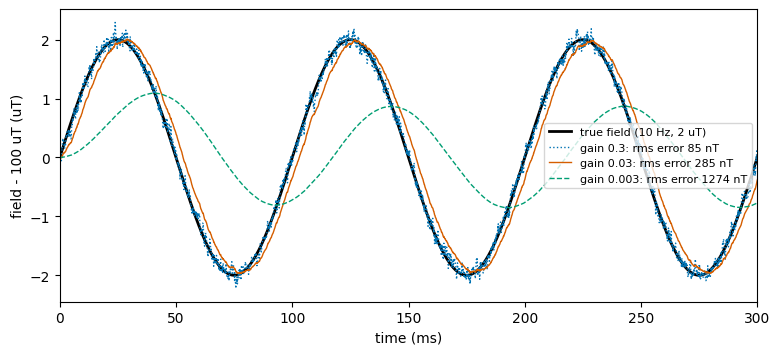

Figure description: the true 10 Hz field (thick black) and three tracked estimates. High gain (dotted) follows closely but is noisy; medium gain (solid) is smoother but lags slightly; low gain (dashed) is smooth but lags far behind and underestimates the oscillation.


In [12]:
B = 1e-4 + 2e-6*np.sin(2*np.pi*10*t)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t*1e3, (B-1e-4)*1e6, "k-", lw=2, label="true field (10 Hz, 2 uT)")
for g, ls in ((0.3, ":"), (0.03, "-"), (0.003, "--")):
    est = L.track_field(B, t, photon_rate=1e13, gain=g)
    ax.plot(t*1e3, (est-1e-4)*1e6, ls=ls, lw=1, label=f"gain {g}: rms error {np.sqrt(np.mean((est[2000:]-B[2000:])**2))*1e9:.0f} nT")
ax.set_xlim(0, 300); ax.set_xlabel("time (ms)"); ax.set_ylabel("field - 100 uT (uT)"); ax.legend(fontsize=8); plt.show()
print("Figure description: the true 10 Hz field (thick black) and three tracked estimates. High gain (dotted) follows "
      "closely but is noisy; medium gain (solid) is smoother but lags slightly; low gain (dashed) is smooth but lags "
      "far behind and underestimates the oscillation.")

This is the central trade-off of every feedback-locked sensor, including PLLs, laser locks and
atomic clocks:
* **high loop gain:** follows fast changes but lets more noise through (wider bandwidth);
* **low loop gain:** averages noise down but lags behind the signal.

The best gain depends on how fast the field you care about changes. Here, gain 0.3 wins for a
10 Hz signal, at 85 nT RMS. A slower field would favor lower gain.

## 6. Summary

| idea | result |
|---|---|
| demodulation | $X=A\cos\phi$, $Y=A\sin\phi$, $R=A$ |
| square-wave reference | also hears $3\omega,5\omega,\dots$ at $1/3,1/5,\dots$ |
| noise bandwidth | $1/4\tau,\ 1/8\tau,\ 3/32\tau,\ 5/64\tau$ for 1–4 poles |
| vs 1/f noise | lock-in at 1 kHz: about 20–30× smaller scatter than switched DC |
| FM on ODMR | output $\approx\delta S'$; optimum $\delta=\Gamma/2\sqrt2$ |
| tracking loop | $\sigma_B\propto\sqrt{g/(2-g)}$; simulation within a few % of theory |

**Connections to the rest of the repo:**
* The lock-in is a matched filter and a narrow band-pass, the same Fourier toolkit as `fourier_tools`.
* The feedback loop is `pid_controller` with only the I term.
* PDH laser locking (mentioned in `pid_controller`) is the same dispersive-error-signal idea, applied to an optical cavity.

*Synthetic data; civilian education.*